# Diabetes Prediction Using Machine Learning

## Feature Engineering and Feature Selection




## 1. Import Required Libraries



In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, mutual_info_classif
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler

try:
    from IPython.display import Image, display
except ImportError:
    Image = None
    def display(value):
        print(value)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)


## 2. Load Cleaned Dataset



In [4]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_RELATIVE_PATH = Path("data") / "processed" / "diabetes_cleaned.csv"
TABLES_RELATIVE_DIR = Path("outputs") / "tables" / "week_08"
FIGURES_RELATIVE_DIR = Path("outputs") / "figures" / "week_08"

DATASET_PATH = PROJECT_ROOT / DATASET_RELATIVE_PATH
TABLES_DIR = PROJECT_ROOT / TABLES_RELATIVE_DIR
FIGURES_DIR = PROJECT_ROOT / FIGURES_RELATIVE_DIR

if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Cleaned dataset not found: {DATASET_RELATIVE_PATH}")

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATASET_PATH)
print("Cleaned dataset loaded successfully.")
print(f"Dataset path: {DATASET_RELATIVE_PATH}")
print(f"Dataset shape: {df.shape}")
display(df.head())


Cleaned dataset loaded successfully.
Dataset path: data\processed\diabetes_cleaned.csv
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


## 3. Verify Columns and Separate X and y

`X` contains input features and `y` contains the target variable `Outcome`. The target is not included in feature-selection inputs.


In [5]:
EXPECTED_COLUMNS = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome",
]

missing_columns = [column for column in EXPECTED_COLUMNS if column not in df.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

if int(df.isna().sum().sum()) != 0:
    raise ValueError("Cleaned dataset contains missing values. Please check Week 6 preprocessing.")

X = df.drop(columns="Outcome")
y = df["Outcome"]
FEATURE_COLUMNS = list(X.columns)

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print("Input features:", FEATURE_COLUMNS)
print("Target variable: Outcome")


X shape: (768, 8)
y shape: (768,)
Input features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Target variable: Outcome


## 5. Correlation with Outcome

Correlation measures the linear relationship between each input feature and the target variable. Absolute correlation is used for ranking because both positive and negative relationships can be useful.


In [6]:
correlation_scores = X.corrwith(y).abs().sort_values(ascending=False)
correlation_ranking = correlation_scores.reset_index()
correlation_ranking.columns = ["feature_name", "absolute_correlation_with_outcome"]
correlation_ranking["correlation_rank"] = range(1, len(correlation_ranking) + 1)
correlation_ranking.to_csv(TABLES_DIR / "correlation_ranking.csv", index=False)
display(correlation_ranking)


,feature_name,absolute_correlation_with_outcome,correlation_rank
0,Glucose,0.492782,1
1,BMI,0.312038,2
2,Age,0.238356,3
3,Pregnancies,0.221898,4
4,SkinThickness,0.214873,5
5,Insulin,0.203790,6
6,DiabetesPedigreeFunction,0.173844,7
7,BloodPressure,0.165723,8


## 6. Mutual Information

Mutual Information can capture non-linear dependency between each feature and the target. Higher scores suggest that a feature contains more information about the target class.


In [7]:
mi_scores = pd.Series(mutual_info_classif(X, y, random_state=RANDOM_STATE), index=FEATURE_COLUMNS).sort_values(ascending=False)
mutual_information_scores = mi_scores.reset_index()
mutual_information_scores.columns = ["feature_name", "mutual_information_score"]
mutual_information_scores["mutual_information_rank"] = range(1, len(mutual_information_scores) + 1)
mutual_information_scores.to_csv(TABLES_DIR / "mutual_information_scores.csv", index=False)
display(mutual_information_scores)


,feature_name,mutual_information_score,mutual_information_rank
0,Glucose,0.117733,1
1,BMI,0.081040,2
2,Pregnancies,0.060985,3
3,Age,0.051395,4
4,DiabetesPedigreeFunction,0.014590,5
5,Insulin,0.012804,6
6,SkinThickness,0.012372,7
7,BloodPressure,0.001763,8


### Mutual Information Bar Chart

This chart shows which features have higher information value for the target. It is used only for feature selection, not for model evaluation.


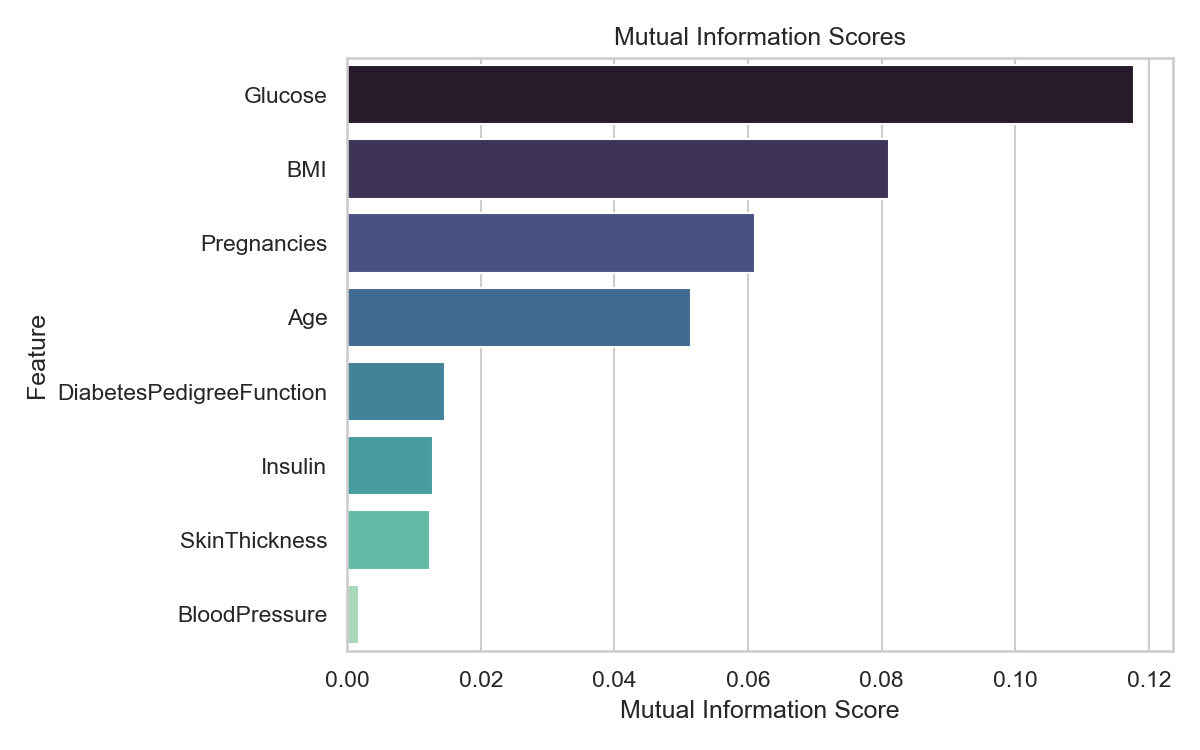

In [8]:
plt.figure(figsize=(8, 5))
sns.barplot(data=mutual_information_scores, x="mutual_information_score", y="feature_name", hue="feature_name", palette="mako", legend=False)
plt.title("Mutual Information Scores")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")
plt.tight_layout()
mi_figure_path = FIGURES_DIR / "mutual_information_bar.png"
plt.savefig(mi_figure_path, dpi=150)
plt.close()
if Image is not None:
    display(Image(filename=str(mi_figure_path)))


## 7. Random Forest Feature Importance

A Random Forest classifier is fitted only to calculate feature importance scores. This is not the final model and no model evaluation is performed here. Higher importance means the feature contributed more to tree-based splitting decisions.


In [10]:
rf_selector = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    class_weight="balanced",
)
rf_selector.fit(X, y)

rf_scores = pd.Series(rf_selector.feature_importances_, index=FEATURE_COLUMNS).sort_values(ascending=False)
feature_importance_random_forest = rf_scores.reset_index()
feature_importance_random_forest.columns = ["feature_name", "random_forest_importance"]
feature_importance_random_forest["random_forest_rank"] = range(1, len(feature_importance_random_forest) + 1)
feature_importance_random_forest.to_csv(TABLES_DIR / "feature_importance_random_forest.csv", index=False)
display(feature_importance_random_forest)


,feature_name,random_forest_importance,random_forest_rank
0,Glucose,0.260284,1
1,BMI,0.170330,2
2,Age,0.138453,3
3,DiabetesPedigreeFunction,0.117040,4
4,Insulin,0.089193,5
5,BloodPressure,0.078002,6
6,Pregnancies,0.076598,7
7,SkinThickness,0.070100,8


### Random Forest Importance Bar Chart

This chart compares feature importance from the Random Forest selection method. It helps identify strong predictors for later modelling.


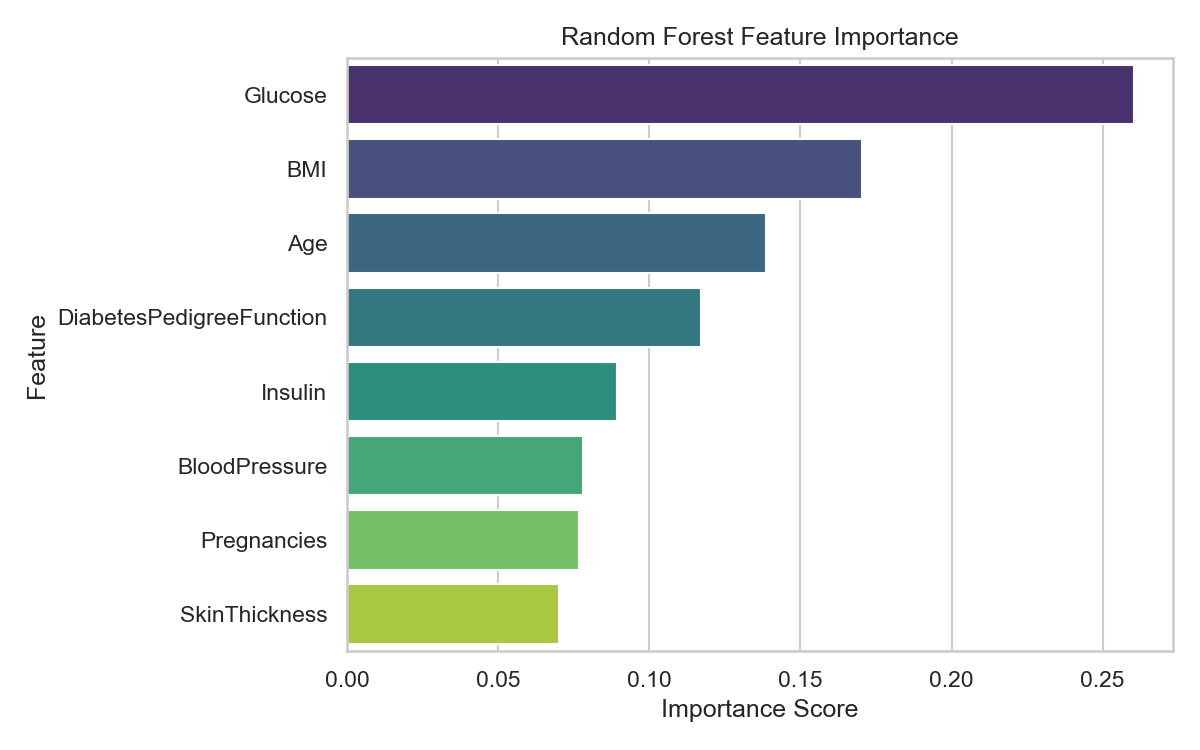

In [11]:
plt.figure(figsize=(8, 5))
sns.barplot(data=feature_importance_random_forest, x="random_forest_importance", y="feature_name", hue="feature_name", palette="viridis", legend=False)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
rf_figure_path = FIGURES_DIR / "feature_importance_bar.png"
plt.savefig(rf_figure_path, dpi=150)
plt.close()
if Image is not None:
    display(Image(filename=str(rf_figure_path)))


## 8. Recursive Feature Elimination

RFE repeatedly removes weaker features based on an estimator. Here, Logistic Regression is used only inside RFE for feature ranking. Features are scaled internally before RFE because Logistic Regression is sensitive to feature scale. This is still feature selection, not final model training or evaluation.


In [12]:
scaler_for_rfe = StandardScaler()
X_scaled_for_rfe = scaler_for_rfe.fit_transform(X)

rfe_estimator = LogisticRegression(
    max_iter=1000,
    solver="liblinear",
    random_state=RANDOM_STATE,
    class_weight="balanced",
)
rfe_selector = RFE(estimator=rfe_estimator, n_features_to_select=5)
rfe_selector.fit(X_scaled_for_rfe, y)

rfe_ranking = pd.DataFrame({
    "feature_name": FEATURE_COLUMNS,
    "rfe_rank": rfe_selector.ranking_,
    "rfe_selected": rfe_selector.support_,
}).sort_values(["rfe_rank", "feature_name"]).reset_index(drop=True)
rfe_ranking.to_csv(TABLES_DIR / "rfe_ranking.csv", index=False)
display(rfe_ranking)


,feature_name,rfe_rank,rfe_selected
0,Age,1,True
1,BMI,1,True
2,DiabetesPedigreeFunction,1,True
3,Glucose,1,True
4,Pregnancies,1,True
5,BloodPressure,2,False
6,Insulin,3,False
7,SkinThickness,4,False


## 9. Variance Inflation Factor

VIF checks multicollinearity among input features. A VIF below 5 is usually acceptable for this project. High VIF would mean a feature is strongly explained by other input features.


In [15]:
vif_rows = []
for index, feature in enumerate(FEATURE_COLUMNS):
    target_feature = X_scaled_for_rfe[:, index]
    other_features = np.delete(X_scaled_for_rfe, index, axis=1)
    vif_model = LinearRegression()
    vif_model.fit(other_features, target_feature)
    r_squared = vif_model.score(other_features, target_feature)
    vif_value = np.inf if r_squared >= 1 else 1 / (1 - r_squared)
    vif_rows.append({
        "feature_name": feature,
        "r_squared_with_other_features": round(float(r_squared), 6),
        "vif_score": round(float(vif_value), 4),
        "multicollinearity_status": "High multicollinearity" if vif_value >= 5 else "Acceptable",
    })

vif_scores = pd.DataFrame(vif_rows).sort_values("vif_score", ascending=False).reset_index(drop=True)
vif_scores.to_csv(TABLES_DIR / "vif_scores.csv", index=False)
display(vif_scores)


,feature_name,r_squared_with_other_features,vif_score,multicollinearity_status
0,Age,0.381242,1.6161,Acceptable
1,BMI,0.364105,1.5726,Acceptable
2,SkinThickness,0.310834,1.4510,Acceptable
3,Pregnancies,0.300927,1.4305,Acceptable
4,Glucose,0.265415,1.3613,Acceptable
5,BloodPressure,0.195281,1.2427,Acceptable
6,Insulin,0.193153,1.2394,Acceptable
7,DiabetesPedigreeFunction,0.046157,1.0484,Acceptable


### VIF Bar Chart

The VIF chart shows whether any feature has problematic multicollinearity. The red line marks the VIF value of 5.


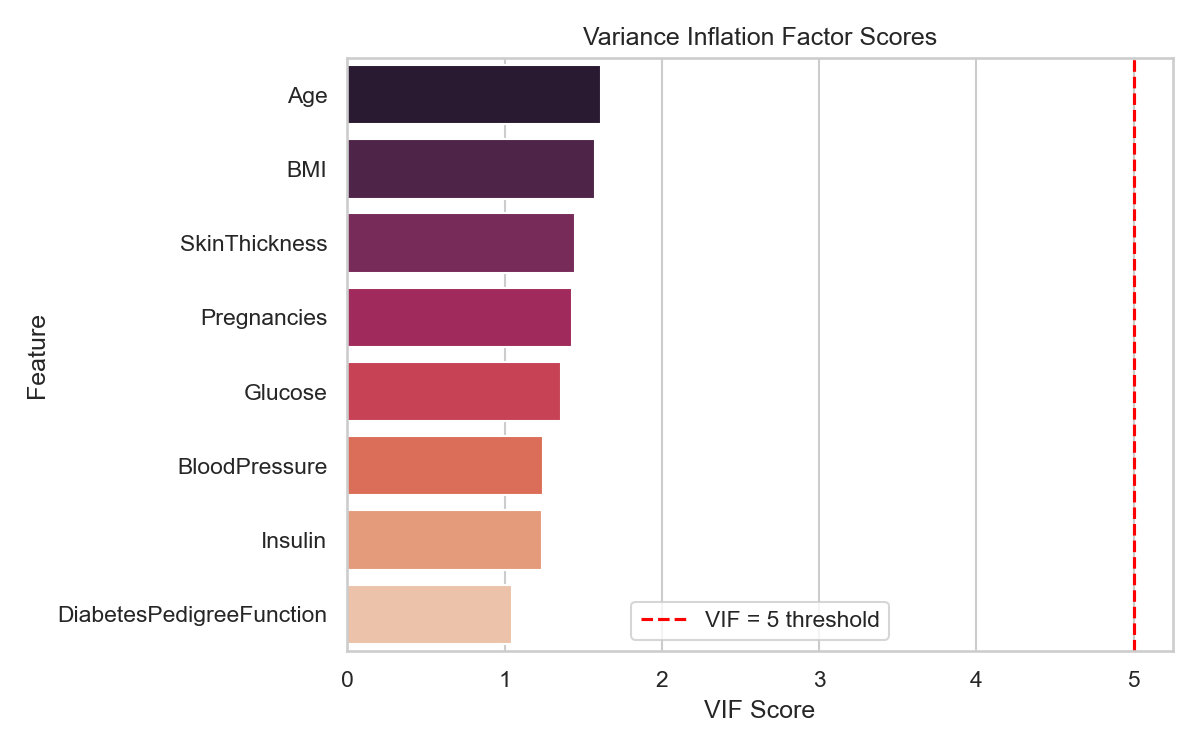

In [16]:
plt.figure(figsize=(8, 5))
sns.barplot(data=vif_scores, x="vif_score", y="feature_name", hue="feature_name", palette="rocket", legend=False)
plt.axvline(5, color="red", linestyle="--", label="VIF = 5 threshold")
plt.title("Variance Inflation Factor Scores")
plt.xlabel("VIF Score")
plt.ylabel("Feature")
plt.legend()
plt.tight_layout()
vif_figure_path = FIGURES_DIR / "vif_bar.png"
plt.savefig(vif_figure_path, dpi=150)
plt.close()
if Image is not None:
    display(Image(filename=str(vif_figure_path)))


### Multicollinearity Finding

The maximum VIF is `1.6161` for `Age`. Since all VIF scores are below 5, no serious multicollinearity is detected among the input features.


## 10. Comparison of Feature-Selection Methods

This comparison table shows how every feature ranks across all methods. A feature receives support when it is in the top five for correlation, mutual information, Random Forest importance, or selected by RFE.


In [17]:
comparison = pd.DataFrame({"feature_name": FEATURE_COLUMNS})
comparison = comparison.merge(correlation_ranking[["feature_name", "absolute_correlation_with_outcome", "correlation_rank"]], on="feature_name")
comparison = comparison.merge(mutual_information_scores[["feature_name", "mutual_information_score", "mutual_information_rank"]], on="feature_name")
comparison = comparison.merge(feature_importance_random_forest[["feature_name", "random_forest_importance", "random_forest_rank"]], on="feature_name")
comparison = comparison.merge(rfe_ranking, on="feature_name")
comparison = comparison.merge(vif_scores[["feature_name", "vif_score", "multicollinearity_status"]], on="feature_name")

comparison["correlation_top5"] = comparison["correlation_rank"] <= 5
comparison["mutual_information_top5"] = comparison["mutual_information_rank"] <= 5
comparison["random_forest_top5"] = comparison["random_forest_rank"] <= 5
comparison["vif_acceptable"] = comparison["vif_score"] < 5
comparison["selection_support_count"] = comparison[["correlation_top5", "mutual_information_top5", "random_forest_top5", "rfe_selected"]].sum(axis=1)
comparison["final_selected"] = (comparison["selection_support_count"] >= 3) & comparison["vif_acceptable"]
comparison = comparison.sort_values(["final_selected", "selection_support_count", "correlation_rank"], ascending=[False, False, True]).reset_index(drop=True)
comparison.to_csv(TABLES_DIR / "feature_selection_comparison.csv", index=False)
display(comparison)


,feature_name,absolute_correlation_with_outcome,correlation_rank,mutual_information_score,mutual_information_rank,random_forest_importance,random_forest_rank,rfe_rank,rfe_selected,vif_score,multicollinearity_status,correlation_top5,mutual_information_top5,random_forest_top5,vif_acceptable,selection_support_count,final_selected
0,Glucose,0.492782,1,0.117733,1,0.260284,1,1,True,1.3613,Acceptable,True,True,True,True,4,True
1,BMI,0.312038,2,0.081040,2,0.170330,2,1,True,1.5726,Acceptable,True,True,True,True,4,True
2,Age,0.238356,3,0.051395,4,0.138453,3,1,True,1.6161,Acceptable,True,True,True,True,4,True
3,Pregnancies,0.221898,4,0.060985,3,0.076598,7,1,True,1.4305,Acceptable,True,True,False,True,3,True
4,DiabetesPedigreeFunction,0.173844,7,0.014590,5,0.117040,4,1,True,1.0484,Acceptable,False,True,True,True,3,True
5,SkinThickness,0.214873,5,0.012372,7,0.070100,8,4,False,1.4510,Acceptable,True,False,False,True,1,False
6,Insulin,0.203790,6,0.012804,6,0.089193,5,3,False,1.2394,Acceptable,False,False,True,True,1,False
7,BloodPressure,0.165723,8,0.001763,8,0.078002,6,2,False,1.2427,Acceptable,False,False,False,True,0,False


## 11. Final Feature Selection Decision

The final rule keeps features supported by at least three of the four selection methods and having acceptable VIF. This balances statistical relationship, non-linear information, tree-based importance, recursive elimination, and multicollinearity checking.


In [18]:
reason_map = {
    "Glucose": "Kept because it ranked first in correlation, mutual information, and Random Forest importance, and was selected by RFE.",
    "BMI": "Kept because it ranked second in correlation, mutual information, and Random Forest importance, and was selected by RFE.",
    "Age": "Kept because it was consistently supported by all four feature-selection methods.",
    "Pregnancies": "Kept because correlation, mutual information, and RFE supported it, and VIF was acceptable.",
    "DiabetesPedigreeFunction": "Kept because mutual information, Random Forest, and RFE supported it, and VIF was acceptable.",
    "SkinThickness": "Removed because only correlation placed it in the top five; other methods gave weaker support.",
    "Insulin": "Removed because only Random Forest placed it in the top five; other methods gave weaker support.",
    "BloodPressure": "Removed because it was not selected by the main ranking methods and had the lowest support count.",
}

final_selected_features = comparison[["feature_name", "final_selected", "selection_support_count", "vif_score"]].copy()
final_selected_features["decision"] = final_selected_features["final_selected"].map({True: "Keep", False: "Remove"})
final_selected_features["justification"] = final_selected_features["feature_name"].map(reason_map)
final_selected_features = final_selected_features.sort_values(["final_selected", "selection_support_count"], ascending=[False, False]).reset_index(drop=True)
final_selected_features.to_csv(TABLES_DIR / "final_selected_features.csv", index=False)
display(final_selected_features)

selected_features = final_selected_features.loc[final_selected_features["final_selected"], "feature_name"].tolist()
removed_features = final_selected_features.loc[~final_selected_features["final_selected"], "feature_name"].tolist()

print("Selected features:", selected_features)
print("Removed features:", removed_features)


,feature_name,final_selected,selection_support_count,vif_score,decision,justification
0,Glucose,True,4,1.3613,Keep,"Kept because it ranked first in correlation, m..."
1,BMI,True,4,1.5726,Keep,"Kept because it ranked second in correlation, ..."
2,Age,True,4,1.6161,Keep,Kept because it was consistently supported by ...
3,Pregnancies,True,3,1.4305,Keep,"Kept because correlation, mutual information, ..."
4,DiabetesPedigreeFunction,True,3,1.0484,Keep,"Kept because mutual information, Random Forest..."
5,SkinThickness,False,1,1.4510,Remove,Removed because only correlation placed it in ...
6,Insulin,False,1,1.2394,Remove,Removed because only Random Forest placed it i...
7,BloodPressure,False,0,1.2427,Remove,Removed because it was not selected by the mai...


Selected features: ['Glucose', 'BMI', 'Age', 'Pregnancies', 'DiabetesPedigreeFunction']
Removed features: ['SkinThickness', 'Insulin', 'BloodPressure']


### Final Feature Selection Decision

The recommended feature list  is: `Glucose, BMI, Age, Pregnancies, DiabetesPedigreeFunction`.

These features are appropriate because they are supported by multiple selection methods and do not show problematic multicollinearity. `Glucose` and `BMI` are especially strong because they rank highly across correlation, mutual information, and Random Forest importance. `Age`, `Pregnancies`, and `DiabetesPedigreeFunction` also add useful patient-history information.

The removed features are: `SkinThickness, Insulin, BloodPressure`. They are not deleted from the project dataset, but they are not recommended for the first Week 9 modelling experiment because they received weaker support from the selection methods.


## 12. Save Output Check

This final check confirms that all required output tables and figures were created.


In [20]:
required_tables = [
    "feature_importance_random_forest.csv",
    "mutual_information_scores.csv",
    "correlation_ranking.csv",
    "rfe_ranking.csv",
    "vif_scores.csv",
    "final_selected_features.csv",
]
required_figures = [
    "feature_importance_bar.png",
    "mutual_information_bar.png",
    "vif_bar.png",
]

for table_name in required_tables:
    table_path = TABLES_DIR / table_name
    if not table_path.exists():
        raise FileNotFoundError(f"Missing table: {table_path}")

for figure_name in required_figures:
    figure_path = FIGURES_DIR / figure_name
    if not figure_path.exists():
        raise FileNotFoundError(f"Missing figure: {figure_path}")

print("All required tables and figures were created successfully.")


All required tables and figures were created successfully.
